In [32]:
import pandas as pd
import seaborn as sns
import scipy as stats

from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.stats import pearsonr, spearmanr, kendalltau

df = pd.read_csv('ds_salaries.csv',index_col = 0)
display(df.head())

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,company_location,company_size
0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,DE,L
1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,JP,S
2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,GB,M
3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,HN,S
4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,US,L


In [33]:
print("Информация о данных")
df.info()

Информация о данных
<class 'pandas.DataFrame'>
RangeIndex: 607 entries, 0 to 606
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           607 non-null    int64
 1   experience_level    607 non-null    str  
 2   employment_type     607 non-null    str  
 3   job_title           607 non-null    str  
 4   salary              607 non-null    int64
 5   salary_currency     607 non-null    str  
 6   salary_in_usd       607 non-null    int64
 7   employee_residence  607 non-null    str  
 8   company_location    607 non-null    str  
 9   company_size        607 non-null    str  
dtypes: int64(3), str(7)
memory usage: 47.6 KB


In [34]:
df.work_year.unique() # дискретные

array([2020, 2021, 2022])

In [35]:
print(df.experience_level.unique()) #порядковые
level_mapping = {'JN': 1, 'MI': 2, 'SE': 3, 'TL': 4}
df['experience_level_num'] = df['experience_level'].map(level_mapping)

<StringArray>
['MI', 'SE', 'JN', 'TL']
Length: 4, dtype: str


In [36]:
df.company_size.unique() #порядковые
size_mapping = {'S': 1, 'M': 2, 'L': 3}
df['company_size_num'] = df['company_size'].map(size_mapping)

In [37]:
display(df.head())

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,company_location,company_size,experience_level_num,company_size_num
0,2020,MI,FT,Data Scientist,70000,EUR,79833,DE,DE,L,2,3
1,2020,SE,FT,Machine Learning Scientist,260000,USD,260000,JP,JP,S,3,1
2,2020,SE,FT,Big Data Engineer,85000,GBP,109024,GB,GB,M,3,2
3,2020,MI,FT,Product Data Analyst,20000,USD,20000,HN,HN,S,2,1
4,2020,SE,FT,Machine Learning Engineer,150000,USD,150000,US,US,L,3,3


# Что оказывает наибольшее влияние на зарплатную вилку в вакансии?

<Axes: xlabel='salary_in_usd'>

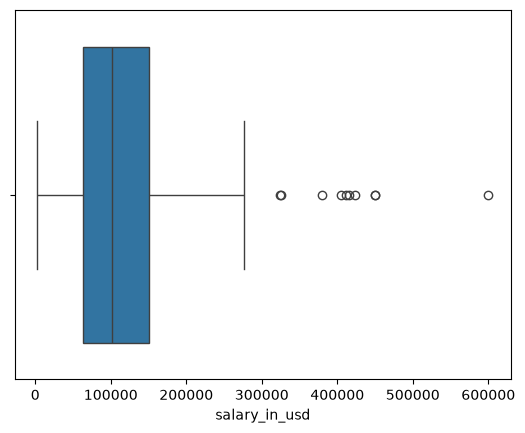

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(
    data=df, 
    x='salary_in_usd')

In [39]:
df = df[df.salary_in_usd <300000]

Убрала выбросы, чтобы они не влияли на последующее изучение. 
Корреляция применяется либо между непрерывными переменными, либо между порядковыми. Порядковыми переменными мы выделили experience_level и company_size

In [40]:
spearmanr(df['salary_in_usd'], df['experience_level_num'])
#Связь сильная, статистически значимая

SignificanceResult(statistic=np.float64(0.5579476468827914), pvalue=np.float64(3.795022662679326e-50))

<Axes: xlabel='salary_in_usd', ylabel='Count'>

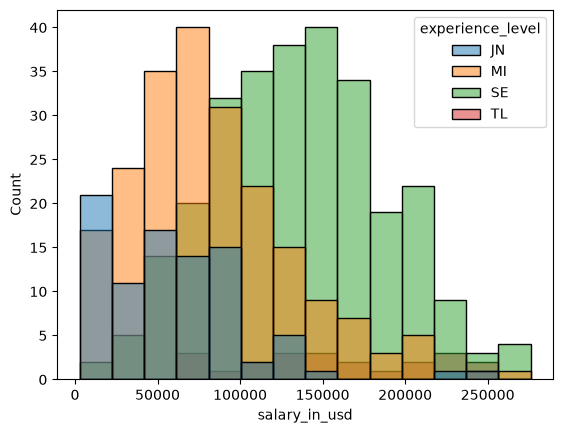

In [41]:
sns.histplot(data=df, x='salary_in_usd',hue='experience_level', hue_order=['JN', 'MI', 'SE', 'TL'])

Строю сгруппированную столбчатую диаграмму, чтобы увидеть, как распределяются грейды внутри компаний разного размера. Шаг необзятаельный, сделан для визуализации данных

In [42]:
spearmanr(df['salary_in_usd'], df['company_size_num'])
#Связь не сильная, статистически значимая

SignificanceResult(statistic=np.float64(0.10308939513387676), pvalue=np.float64(0.011726080444722028))

Больше на зарплату влияет опыт. Влияние размера компании невелико.

# Как распределены позиции сотрудников в компаниях разного размера и какие выводы можно сделать из полученного распределения?

([<matplotlib.axis.XTick at 0x1be45a482d0>,
 [Text(0, 0, 'S'), Text(1, 0, 'M'), Text(2, 0, 'L')])

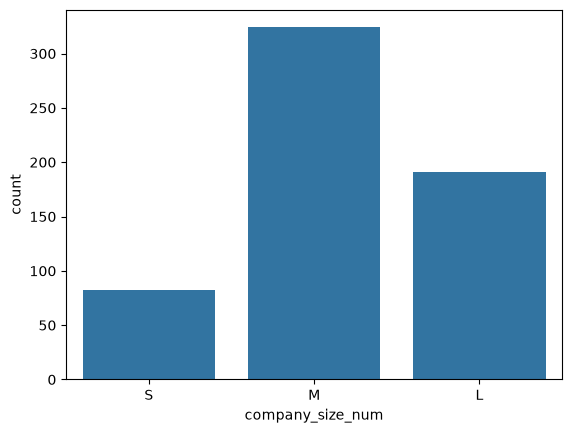

In [43]:
sns.countplot(data = df, x='company_size_num')
plt.xticks(ticks=[0, 1, 2], labels=['S', 'M', 'L'])

([<matplotlib.axis.XTick at 0x1be45a78f50>,
 [Text(0, 0, 'JN'), Text(1, 0, 'MI'), Text(2, 0, 'SE'), Text(3, 0, 'TL')])

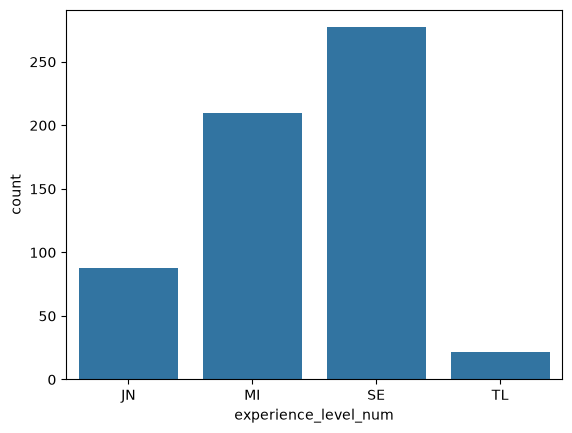

In [44]:
sns.countplot(data = df, x='experience_level_num')
plt.xticks(ticks=[0, 1, 2, 3], labels=['JN', 'MI', 'SE','TL'])

<Axes: xlabel='company_size', ylabel='count'>

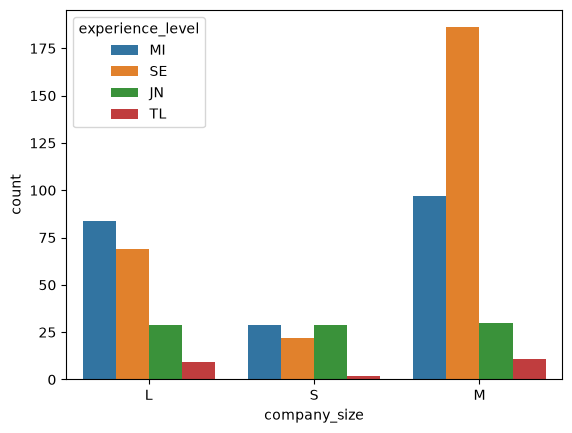

In [45]:
sns.countplot(data=df, x='company_size',hue='experience_level')

малые компании чаще набирают мидл или джуниор работников.
средние - сеньёров.
большие - мидл.
Тимлидов набирают больше всего средние компании.

<Axes: xlabel='salary_in_usd', ylabel='experience_level'>

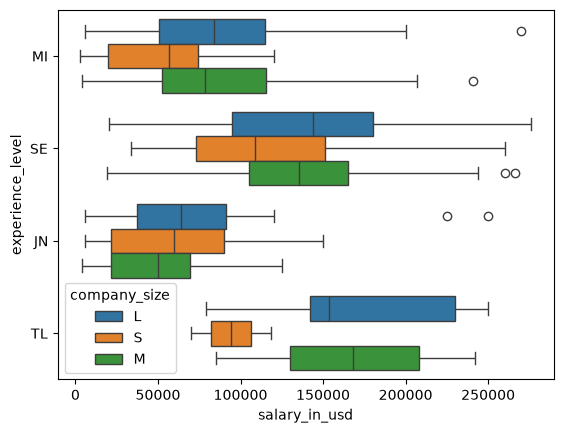

In [46]:
sns.boxplot(data=df, x='salary_in_usd', y='experience_level', hue = 'company_size')

# В какую компанию выгодней устраиваться сотруднику с опытом Мидл или Сеньёр?

In [47]:
middle = df[df.experience_level == 'MI']
middle.shape

(210, 12)

<Axes: xlabel='salary_in_usd', ylabel='Count'>

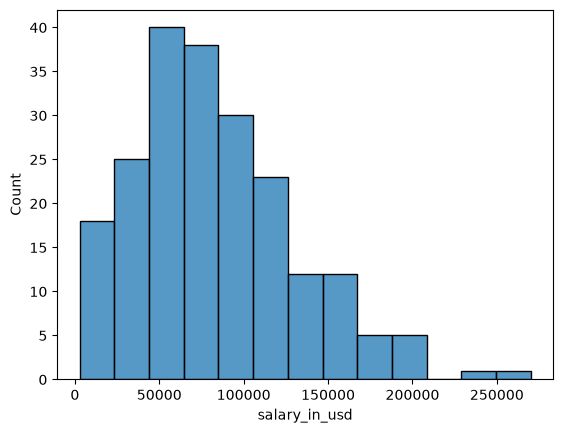

In [48]:
sns.histplot(data=middle, x='salary_in_usd')

Применяю Box-Cox, так как распределение зарплат мидлов имеет правостороннюю асимметрию, а ANOVA требует нормальности остатков.

In [49]:
tr_data, l = stats.stats.boxcox(middle.salary_in_usd)

<Axes: ylabel='Count'>

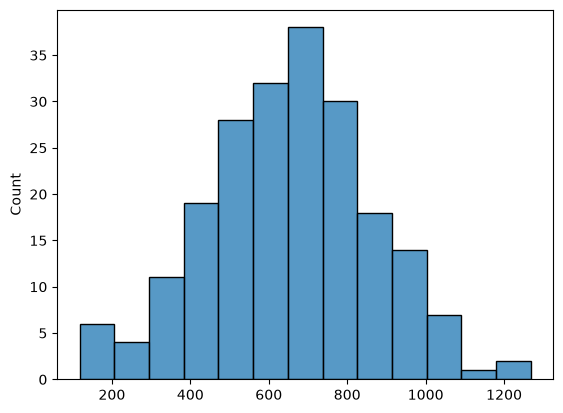

In [50]:
sns.histplot(tr_data)

In [51]:
middle = middle.copy()
middle['salary_in_usd'] = middle['salary_in_usd'].astype(float)

middle.loc[:, 'salary_in_usd'] = tr_data

In [52]:
one_way= ols('salary_in_usd ~ company_size', middle).fit()
anova_lm(one_way)

,df,sum_sq,mean_sq,F,PR(>F)
company_size,2.0,7.797339e+05,389866.933074,9.229123,0.000145
Residual,207.0,8.744325e+06,42243.116633,NaN,NaN


p-value < 0.05, значит, размер компании значимо влияет на зарплату мидлов. Перехожу к тесту Тьюки, чтобы узнать, между какими именно размерами компаний есть разница

In [53]:
middle_s = middle[middle.company_size == 'S'].salary_in_usd
middle_m = middle[middle.company_size == 'M'].salary_in_usd
middle_l = middle[middle.company_size == 'L'].salary_in_usd

In [54]:
stats.stats.levene(middle_s, middle_m, middle_l)

LeveneResult(statistic=np.float64(0.5807501532259973), pvalue=np.float64(0.5603874299118398))

Равенство дисперсий есть. Однако, если бы его не было, мы могли бы это проигнорировать ввиду маленького размера выборки. 
Это нужно, чтобы убедиться, что условия для ANOVA соблюдены.

In [55]:
print(pairwise_tukeyhsd(endog=middle.salary_in_usd, alpha=0.05, groups=middle['company_size']))

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower    upper   reject
--------------------------------------------------------
     L      M  -10.7662 0.9342  -83.0818  61.5494  False
     L      S -181.7997 0.0002 -286.3003 -77.2991   True
     M      S -171.0335 0.0003 -273.7212 -68.3458   True
--------------------------------------------------------


<Axes: xlabel='salary_in_usd', ylabel='company_size'>

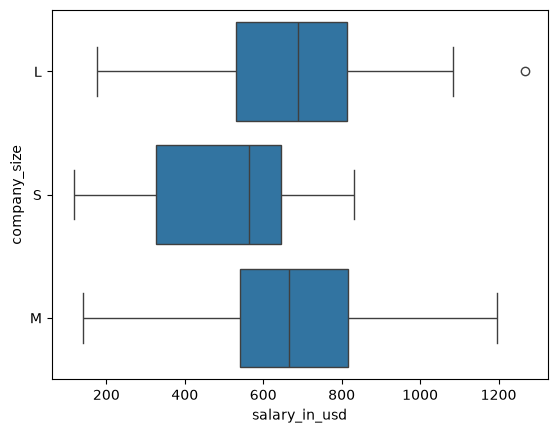

In [56]:
sns.boxplot(data=middle, x='salary_in_usd', y='company_size')

Для содрутника с опытом мидл больше подходят компании размена L или M

In [59]:
senior = df[df.experience_level == 'SE']
senior.shape

(277, 12)

<Axes: xlabel='salary_in_usd', ylabel='Count'>

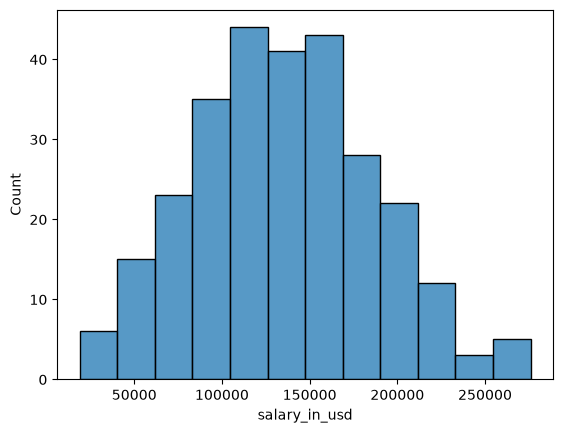

In [60]:
sns.histplot(data=senior, x='salary_in_usd')

Данные нормальны (распределены, как "колокол"), поэтому проводить анализ можно без boxcox.

In [61]:
one_way= ols('salary_in_usd ~ company_size', senior).fit()
anova_lm(one_way)

,df,sum_sq,mean_sq,F,PR(>F)
company_size,2.0,9.408313e+09,4.704156e+09,1.807669,0.165987
Residual,274.0,7.130390e+11,2.602332e+09,NaN,NaN


<Axes: xlabel='salary_in_usd', ylabel='company_size'>

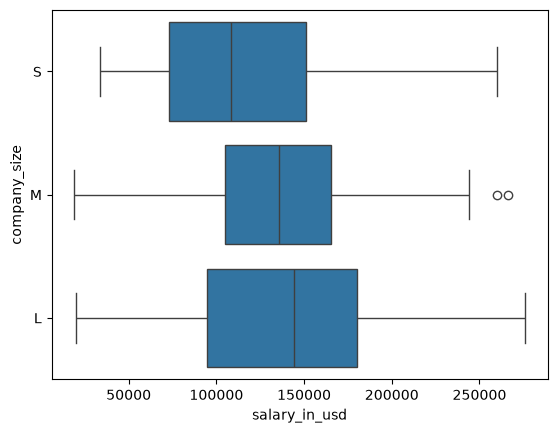

In [62]:
sns.boxplot(data=senior, x='salary_in_usd', y='company_size')

Зарплата Сеньёр специалиста почти не заисит от размера компании